# Spatial CNV inference on Xenium

Imaging-based spatial transcriptomics (Xenium, CosMx, MERSCOPE) measures a few thousand genes in hundreds of
thousands of cells, with a few hundred counts per cell. inferCNV-style profiles of single cells are noisy at that
depth, but the tissue coordinates add information: neighbouring tumour cells usually share their copy number state.
This tutorial shows the spatial layer of infercnvpy:

- {func}`infercnvpy.tl.smooth_cnv` averages each cell's CNV profile with its spatial neighbours,
- {func}`infercnvpy.tl.spatial_regions` makes per-cell labels (here tumour/normal calls) spatially coherent with a
  Potts prior,
- {func}`infercnvpy.pl.spatial_cnv` plots the mean CNV of a chromosome or arm on the tissue.

All three read a spatial neighbour graph from `adata.obsp`, here from {func}`squidpy.gr.spatial_neighbors_knn`.
squidpy comes with the optional `spatial` extra (`pip install "infercnvpy[spatial]"`); any cells x cells graph works.

The ideas are not new. InSituCNV {cite}`Jensen2025` smooths infercnvpy profiles over kNN neighbours on Xenium and CosMx,
SlideCNA {cite}`Zhang2025` pools spatial neighbours on Slide-seq, and STARCH {cite}`Elyanow2021` and CalicoST
{cite}`Ma2024` put a hidden Markov random field prior on clone labels. In a benchmark of CNV inference on spatial data,
{cite:t}`Han2026` found that aggregating cells of imaging platforms improved CNV recovery compared to native
single-cell resolution.

We use a Xenium Prime 5K section of a squamous cell lung carcinoma (5,001 genes, 64,872 cells, median 232 counts per
cell) from {cite:t}`Bilous2026`, distributed under GEO terms through the scverse spatial data catalogue.
Squamous lung cancers typically lose 3p and gain 3q.

In [1]:
import warnings

import anndata as ad
import numpy as np
import pandas as pd
import pooch
import scanpy as sc
import squidpy as sq
import zarr

import infercnvpy as cnv

warnings.simplefilter("ignore", FutureWarning)
sc.settings.set_figure_params(dpi=50, frameon=False, figsize=(4.5, 4.5))

## Load the data

The dataset is a SpatialData object on S3. We only need its table, which we open lazily with
{func}`anndata.experimental.read_lazy` and then load the counts, the cell metadata and the cell centroids into memory
(about 100 MB). Images, transcripts and segmentation shapes are never downloaded.

In [2]:
group = zarr.open_group(
    "s3://scverse-spatial-eu-central-1/.lamindb/cOjo8Fe6mVpB4Mu0.zarr/tables/table",
    mode="r",
    storage_options={"anon": True},
)
lazy = ad.experimental.read_lazy(group)
adata = ad.AnnData(
    X=lazy.X.compute(),
    obs=lazy.obs.to_memory()[["cell_id", "total_counts", "cell_area"]].reset_index(drop=True),
    var=lazy.var.to_memory()[["gene_ids"]],
    obsm={"spatial": lazy.obsm["spatial"].compute()},
)
adata.obs_names = adata.obs.pop("cell_id").astype(str).to_numpy()
adata

AnnData object with n_obs × n_vars = 64872 × 5001
    obs: 'total_counts', 'cell_area'
    var: 'gene_ids'
    obsm: 'spatial'
    layers: None (.X)

We drop cells with fewer than 50 counts and log-normalise to 10,000 counts per cell. The CNV values are log fold
changes, so the normalisation target sets their scale: with the default target (the median, here about 230 counts),
most values are `log1p` of 0 or 1 count and the differences between cells shrink.

In [3]:
print(f"median counts per cell: {np.median(adata.obs['total_counts']):.0f}")
sc.pp.filter_cells(adata, min_counts=50)
adata.layers["counts"] = adata.X.copy()
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata

median counts per cell: 232


AnnData object with n_obs × n_vars = 56265 × 5001
    obs: 'total_counts', 'cell_area', 'n_counts'
    var: 'gene_ids'
    uns: 'log1p'
    obsm: 'spatial'
    layers: None (.X), 'counts'

## Annotate reference cells

inferCNV compares every cell to normal reference cells. The dataset has no cell type labels, so we cluster the
expression data and annotate the clusters with marker gene scores. The Prime 5K panel leaves out many classic,
highly expressed markers (PTPRC, keratins, collagens), so we use: T, B and myeloid cell markers for immune cells
(CD3E, MS4A1, CD68, ...), PECAM1, CLDN5 and CDH5 for endothelial cells, PDGFRA, PDGFRB and FAP for fibroblasts,
and SOX2, TP63, DSG3 and EPCAM for (squamous) epithelium. Immune cells, endothelial cells and fibroblasts are the
reference; the epithelial cells contain the tumour.

In [4]:
markers = {
    "immune": ["CD2", "CD3E", "CD4", "CD8A", "MS4A1", "CD79A", "MZB1", "CD68", "CD14", "CD163", "CSF1R", "MRC1"],
    "endothelial": ["PECAM1", "CLDN5", "CDH5", "KDR", "PLVAP", "TEK"],
    "fibroblast": ["PDGFRA", "PDGFRB", "FAP", "THY1", "COL5A1", "POSTN"],
    "epithelial": ["SOX2", "TP63", "DSG3", "EPCAM", "CDH1"],
}
markers = {k: [g for g in v if g in adata.var_names] for k, v in markers.items()}
for name, genes in markers.items():
    sc.tl.score_genes(adata, genes, score_name=name, random_state=0)

sc.pp.pca(adata, random_state=0)
sc.pp.neighbors(adata, random_state=0)
sc.tl.leiden(adata, resolution=0.5, flavor="igraph", n_iterations=2, random_state=0)
scores = adata.obs.groupby("leiden", observed=True)[list(markers)].mean()
adata.obs["cell_type"] = adata.obs["leiden"].map(scores.idxmax(axis=1)).astype("category")
scores.round(2).assign(cell_type=scores.idxmax(axis=1), n_cells=adata.obs["leiden"].value_counts())

,immune,endothelial,fibroblast,epithelial,cell_type,n_cells
leiden,,,,,,
0,-0.14,-0.18,2.14,-0.31,fibroblast,5817
1,-0.16,1.32,0.49,-0.27,endothelial,4924
2,-0.06,-0.08,1.41,-0.16,fibroblast,10294
3,0.35,-0.12,-0.06,-0.19,immune,7663
4,0.74,-0.06,-0.04,-0.22,immune,5154
5,-0.52,-0.39,-1.13,0.70,epithelial,1037
6,0.39,0.09,0.20,-0.20,immune,3231
7,-0.03,-0.02,-0.15,0.12,epithelial,3720
8,0.01,-0.03,-0.06,0.01,immune,2063


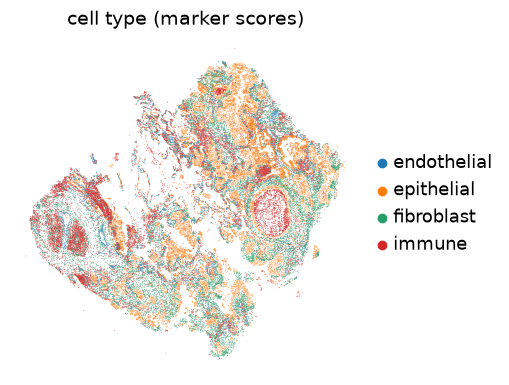

In [5]:
cnv.pl.spatial_cnv(adata, color="cell_type", size=1, title="cell type (marker scores)")

## Gene positions

The genomic positions of the genes come from the GENCODE v44 annotation (about 50 MB, downloaded once with
{mod}`pooch`). The Xenium panel lists Ensembl gene ids, which we match to the GTF.

In [6]:
gtf = pooch.retrieve(
    "https://ftp.ebi.ac.uk/pub/databases/gencode/Gencode_human/release_44/gencode.v44.annotation.gtf.gz",
    known_hash="sha256:01f817afed65feee863361b4baf30a95e722ee5c5d508ff77b04106ef7ba20d3",
    fname="gencode.v44.annotation.gtf.gz",
    path=pooch.os_cache("infercnvpy"),
)
cnv.io.genomic_position_from_gtf(gtf, adata, gtf_gene_id="gene_id", adata_gene_id="gene_ids")
adata.var["chromosome"].value_counts().head()

chromosome
chr1     536
chr17    323
chr11    320
chr2     319
chr19    288
Name: count, dtype: int64

## Infer CNVs and smooth them over the tissue

{func}`infercnvpy.tl.infercnv` runs as for single-cell data. The panel has 100 to 500 genes per chromosome, so we use
running windows of 51 genes, every 5 genes, instead of the defaults (100 and 10). Then we build a spatial graph of the 10 nearest
neighbours of each cell with squidpy and average each cell's CNV profile with its neighbours using
{func}`infercnvpy.tl.smooth_cnv`. By default, the cell itself counts as one more neighbour.

In [7]:
cnv.tl.infercnv(
    adata,
    reference_key="cell_type",
    reference_cat=["immune", "endothelial", "fibroblast"],
    window_size=51,
    step=5,
)
sq.gr.spatial_neighbors_knn(adata, n_neighs=10)
cnv.tl.smooth_cnv(adata)
adata.obsm["X_cnv"].shape, adata.obsm["X_cnv_smoothed"].shape

((56265, 744), (56265, 744))

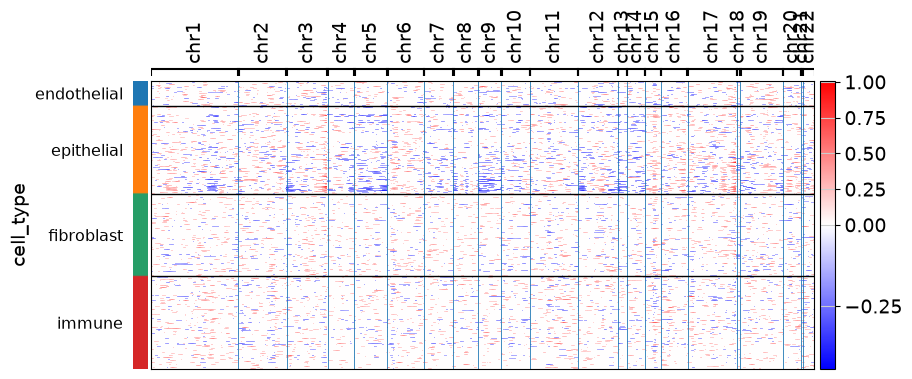

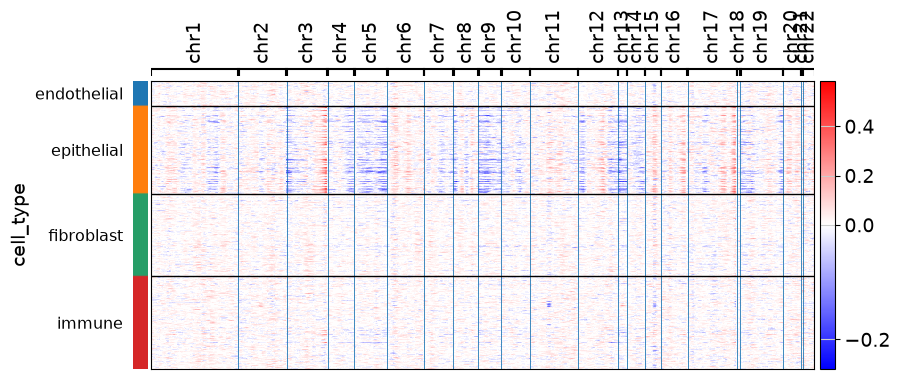

In [8]:
cnv.pl.chromosome_heatmap(adata, groupby="cell_type", figsize=(9, 4))
cnv.pl.chromosome_heatmap(adata, groupby="cell_type", use_rep="cnv_smoothed", figsize=(9, 4))

Smoothing removes most of the noise of single cells. The epithelial cells show the expected loss of 3p and gain of
3q. On the tissue, the mean CNV of each chromosome arm (windows that overlap it, using the window positions that
`tl.infercnv` stores) shows where the tumour is. The centromere of chromosome 3 is at about 91 Mb (GRCh38).

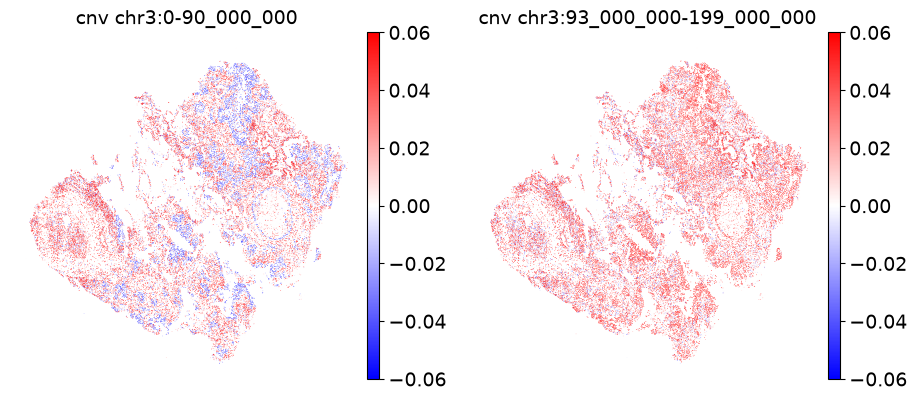

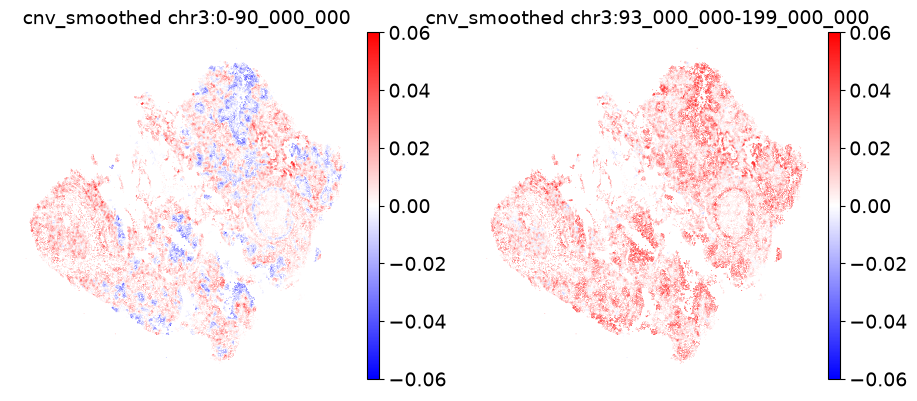

In [9]:
arms = ["chr3:0-90_000_000", "chr3:93_000_000-199_000_000"]
cnv.pl.spatial_cnv(adata, region=arms, size=1, vmin=-0.06, vmax=0.06)
cnv.pl.spatial_cnv(adata, region=arms, use_rep="cnv_smoothed", size=1, vmin=-0.06, vmax=0.06)

## Tumour calls

We cluster the smoothed CNV profiles, score each cluster with {func}`infercnvpy.tl.cnv_score` and call clusters
tumour when their score is above the 95th percentile of the per-cell scores of the reference cells.

In [10]:
cnv.tl.pca(adata, use_rep="cnv_smoothed")
cnv.pp.neighbors(adata)
cnv.tl.leiden(adata, resolution=0.5, random_state=0)
cnv.tl.cnv_score(adata, use_rep="cnv_smoothed")
by_cluster = adata.obs.groupby("cnv_leiden", observed=True).agg(
    cnv_score=("cnv_score", "first"),
    n_cells=("cnv_score", "size"),
    epithelial=("cell_type", lambda x: np.mean(x == "epithelial")),
)
reference = adata.obs["cell_type"].isin(["immune", "endothelial", "fibroblast"])
cell_score = np.abs(adata.obsm["X_cnv_smoothed"]).mean(axis=1)
threshold = np.quantile(cell_score[reference.to_numpy()], 0.95)
adata.obs["cnv_call"] = np.where(adata.obs["cnv_score"] > threshold, "tumour", "normal")
adata.obs["cnv_call"] = adata.obs["cnv_call"].astype("category")
print(f"threshold {threshold:.4f}")
by_cluster.sort_values("cnv_score", ascending=False).round(3).head(15)

threshold 0.0264


,cnv_score,n_cells,epithelial
cnv_leiden,,,
42,0.063,16,1.000
39,0.049,57,0.982
15,0.048,239,0.975
56,0.047,47,0.979
57,0.046,13,1.000
51,0.046,30,0.900
54,0.038,37,0.892
20,0.035,11873,0.784
43,0.034,168,0.810


Most tumour cells fall into one large CNV cluster with the loss of 3p, the gain of 3q and losses on chromosomes 4, 5
and 9. The calls mark epithelial regions of the section. Fibroblasts and immune cells called tumour are probably cells
within or next to tumour nests, whose smoothed profiles mix with those of their tumour neighbours (see the notes at
the end).

In [11]:
pd.crosstab(adata.obs["cell_type"], adata.obs["cnv_call"], normalize="index").round(3)

cnv_call,normal,tumour
cell_type,,
endothelial,0.970,0.030
epithelial,0.405,0.595
fibroblast,0.905,0.095
immune,0.943,0.057


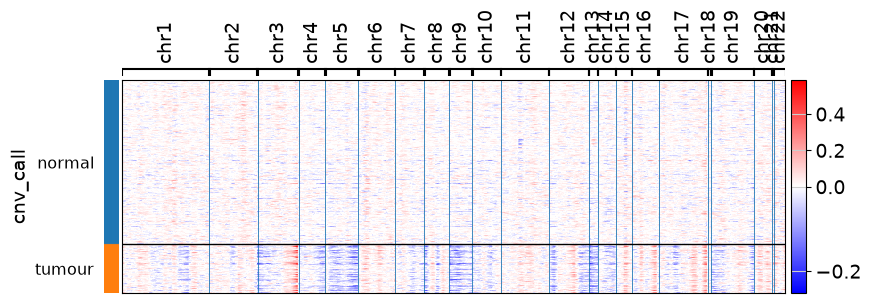

In [12]:
cnv.pl.chromosome_heatmap(adata, groupby="cnv_call", use_rep="cnv_smoothed", figsize=(9, 3))

## Spatially coherent regions

{func}`infercnvpy.tl.spatial_regions` regularises labels with a Potts prior on the spatial graph: a cell takes the
label of its neighbourhood when enough neighbours disagree with it (for two labels and the default `beta=2`, more
than 75% of them). The calls from the smoothed profiles are already spatially coherent, and few cells change.

In [13]:
cnv.tl.spatial_regions(adata, key="cnv_call")
pd.crosstab(adata.obs["cnv_call"], adata.obs["cnv_call_spatial"])

cnv_call_spatial,normal,tumour
cnv_call,,
normal,43340,14
tumour,45,12866


The prior matters more for noisy labels. Calls of single cells from the unsmoothed CNV profiles, with the same rule
(mean absolute CNV above the 95th percentile of the reference cells), are scattered over the section.
With `beta=4` (a cell changes its label when more than 62.5% of its neighbours disagree), `tl.spatial_regions`
removes the scattered calls and keeps the dense tumour regions. It cannot recover tumour cells that the unsmoothed
profiles miss, though: the agreement with the calls from the smoothed profiles only rises from 82% to 85%.
On this section, smoothing the profiles before calling does more than regularising the calls afterwards.

In [14]:
raw_score = np.asarray(abs(adata.obsm["X_cnv"]).mean(axis=1)).ravel()
raw_threshold = np.quantile(raw_score[reference.to_numpy()], 0.95)
adata.obs["cnv_call_raw"] = pd.Categorical(np.where(raw_score > raw_threshold, "tumour", "normal"))
cnv.tl.spatial_regions(adata, key="cnv_call_raw", beta=4)
pd.Series(
    {
        key: np.mean(adata.obs[key].to_numpy() == adata.obs["cnv_call_spatial"].to_numpy())
        for key in ["cnv_call_raw", "cnv_call_raw_spatial"]
    },
    name="agreement with cnv_call_spatial",
).round(3)

cnv_call_raw            0.823
cnv_call_raw_spatial    0.851
Name: agreement with cnv_call_spatial, dtype: float64

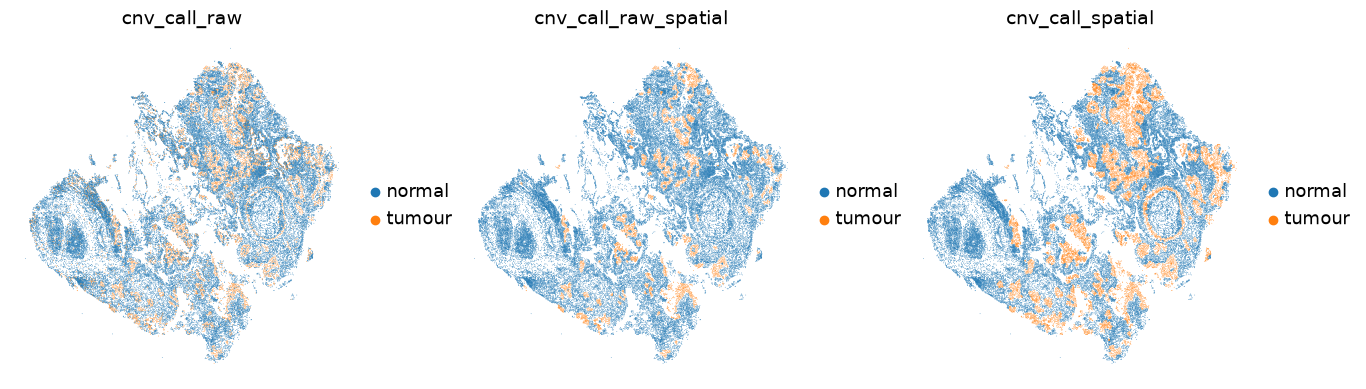

In [15]:
cnv.pl.spatial_cnv(adata, color=["cnv_call_raw", "cnv_call_raw_spatial", "cnv_call_spatial"], size=1)

## Notes

- Smoothing mixes the profiles of tumour and normal cells at the tumour boundary and of immune cells that infiltrate
  the tumour, over about `n_hops` cells. Use the unsmoothed `X_cnv` for per-cell questions in mixed regions.
- The spatial graph defines the neighbourhood. A kNN graph adapts to the cell density; a radius graph
  ({func}`squidpy.gr.spatial_neighbors_radius`) keeps the physical scale fixed. `n_hops=2` in `tl.smooth_cnv`
  widens the neighbourhood further.
- `tl.spatial_regions` returns a local minimum of its energy close to the input labels, not a new clustering. Larger
  `beta` gives smoother regions.